# 00 · Shared protocol: data, warm-up, frozen τ_H, target T4

**PA04 · Textile storage facility (humid vs. dry regimes) · Guimarães (City A) vs Viana do Castelo (City B) · T4 Humid vs Dry Regime**

* **Business context:** textile storage facility (humid vs. dry regimes)
* **Locations:** Guimarães vs Viana do Castelo
* **Question:** How do humid and dry regimes differ between candidate warehouse locations?

| | Student | Number | Primary city |
|---|---|---|---|
| Student A | Khadija Belhamra | 20230007 | City A: Guimarães |
| Student B | Victoriya Mokhovikova | 20230796 | City B: Viana do Castelo |

This is the **shared** notebook that comes first. Both cities must use the *same* target definition, threshold policy, warm-up rule and chronological protocol (Ch. 3.1). All of that is implemented once, in `src/data.py`, and configured once, in `config.yaml`. This notebook calls it and shows the evidence.

| Order | Notebook | Owner | Content |
|---|---|---|---|
| 1 | **00_shared_protocol** (this one) | both | raw data → clean streams → warm-up → frozen τ_H → target T4 → protocol checks |
| 2 | 01_cityA_guimaraes / 02_cityB_viana_do_castelo | Khadija Belhamra (A) / Victoriya Mokhovikova (B) | stream profile of the primary city (Ch. 9) + prequential experiment on that city + individual experiments |
| 3 | 03_shared_comparison | both | pairs both students' results: City A vs City B, model comparison, business answer |

> **Workflow rule:** collect once → save raw → prepare → replay as a stream. Every notebook calls `prepare_frames(cfg)`, so τ_H is computed in one place only (`src/data.py`) and never set by hand.

> **AI policy (Ch. 16):** cells marked *📝 For the report* are for your own interpretation. Write them yourselves.

## 1. Setup, configuration and package versions

**Requirement (Ch. 12.9, 15):** record the package versions, random seed and historical period.

In [1]:
import sys
from pathlib import Path

# Make src/ importable whatever folder Jupyter was started from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import data
import plots
from features import check_no_leakage, make_streams
from utils import load_config, package_version

pd.set_option("display.max_columns", 50)
plots.set_style()
cfg = load_config()

pd.Series({n: package_version(n) for n in ("pandas", "numpy", "river", "scikit-learn", "matplotlib")},
          name="version").to_frame()

,version
pandas,2.3.3
numpy,2.5.4
river,0.26.1
scikit-learn,1.9.1
matplotlib,3.11.2


## 2. Assignment card and shared protocol

Every value below comes from `config.yaml`. Nothing is set separately per city.

In [3]:
p, d = cfg["protocol"], cfg["data"]
pd.Series({
    "Assignment": cfg["project"]["assignment"],
    "Business scenario": cfg["project"]["scenario"],
    "Question": cfg["project"]["business_question"],
    "City A / City B": " / ".join(c["name"] for c in cfg["cities"]),
    "Target": f'{cfg["project"]["target"]}: {cfg["project"]["target_name"]}',
    "Threshold": f'tau_H = Q{p["target_quantile"]:.2f}({p["target_variable"]}) over the pooled warm-up',
    "Historical period": f'{d["start_date"]} to {d["end_date"]} (hourly)',
    "Warm-up": f'first {p["warmup_months"]} months (not scored)',
    "Hourly variables": ", ".join(d["hourly_variables"]),
    "Random seed": p["seed"],
}, name="value").to_frame()

,value
Assignment,PA04
Business scenario,Textile Storage Facility
Question,How do humid and dry regimes differ between ca...
City A / City B,Guimaraes / Viana do Castelo
Target,T4: Humid vs Dry Regime
Threshold,tau_H = Q0.50(relative_humidity_2m) over the p...
Historical period,2023-01-01 to 2025-12-31 (hourly)
Warm-up,first 12 months (not scored)
Hourly variables,"temperature_2m, relative_humidity_2m, precipit..."
Random seed,42


## 3. Raw data snapshots

**Requirement (Ch. 15, 15.2):** save or describe the data snapshots used, so every result can be traced back to them.

* `data.get_snapshot` reuses `data/<city>_raw.json` if it exists (`storage.force_download: false`). Otherwise it downloads it once from the Open-Meteo **Historical Weather** API (reanalysis, not forecasts).
* Raw files are never modified. All cleaning happens in memory. See `data/README.md` for the dataset description.

`prepare_frames` runs the whole shared protocol: snapshots → tables → common timeline → quality flags → warm-up → τ_H → target.

In [4]:
prepared = data.prepare_frames(cfg)
CITIES = {c["key"]: c for c in cfg["cities"]}
frames = prepared["frames"]

Open-Meteo snaps the requested coordinates to its model grid. The **grid point and elevation actually used** belong in the report (*Data and Stream Construction*).

In [5]:
pd.DataFrame([
    {
        "role": c["role"], "city": c["name"],
        "requested_lat": c["latitude"], "requested_lon": c["longitude"],
        "grid_lat": pl.get("latitude"), "grid_lon": pl.get("longitude"),
        "grid_elevation_m": pl.get("elevation"),
        "timezone": pl.get("timezone"), "utc_offset_s": pl.get("utc_offset_seconds"),
        "hours": len(pl["hourly"]["time"]),
    }
    for c, pl in ((CITIES[k], pl) for k, pl in prepared["payloads"].items())
]).set_index("role")

,city,requested_lat,requested_lon,grid_lat,grid_lon,grid_elevation_m,timezone,utc_offset_s,hours
role,,,,,,,,,
City A,Guimaraes,41.4289,-8.31780,41.441124,-8.287781,170.0,Europe/Lisbon,3600,26304
City B,Viana do Castelo,41.6950,-8.82916,41.722317,-8.856751,15.0,Europe/Lisbon,3600,26304


To check whether each grid cell represents its city, we compared the grid-point locations and elevations with the requested coordinates.

- **Guimarães:** The grid point is ~2.9 km NE of the city, at 170 m, close to the city's real altitude (~150–200 m). It's representative, though the hilly terrain nearby means some local variation is smoothed out.
- **Viana do Castelo:** The grid point is ~3.8 km NW, at 15 m, toward the Atlantic shore. It is a coastal cell (confirmed on a map), for that reason it may be slightly more maritime (milder, windier, more humid) than inland parts of Viana.
- **Conclusion:** Both cells are within ~4 km of their cities. The 155 m elevation gap matches the real inland vs. coastal contrast, so both cells are reasonably representative.

## 4. Chronology and timezone

**Requirement (Ch. 12.1):** preserve chronological order. Every later step depends on a regular, strictly increasing hourly index.

Portugal uses summer time (DST). A true local clock would have **one missing hour in March and one duplicated hour in October**. If the steps below are perfectly regular, the API returned a **fixed offset** clock (`utc_offset_seconds`). `to_frame` therefore also stores `timestamp_utc`, so the hour-of-day analyses can use the true local clock.

In [6]:
pd.DataFrame({CITIES[k]["name"]: data.chronology_report(f) for k, f in frames.items()})

,Guimaraes,Viana do Castelo
first,2023-01-01 00:00:00,2023-01-01 00:00:00
last,2025-12-31 23:00:00,2025-12-31 23:00:00
rows,26304,26304
expected_hours,26304,26304
duplicate_timestamps,0,0
non_1h_steps,0,0
strictly_increasing,True,True


**Conclusion:** Both series are complete and strictly hourly, with no duplicates or gaps, which confirms the API used a fixed-offset clock. Since timestamp_utc is stored, hour-of-day analyses can be converted to true local time, so the chronology and DST handling raise no issues.

## 5. Data quality checks

**Requirement (Ch. 9 item 1, Ch. 18):** inspect missing and invalid observations. **Extreme ≠ erroneous**: high humidity or heavy rain may be exactly the event the business cares about.

Rule used in this project (`config.yaml → quality.valid_ranges`, the same for both cities):
* a value is flagged **invalid** only if it is missing or breaks the variable's definition (temperature outside −50 to 60 °C, RH outside 0–100 %, negative precipitation or wind speed);
* flagged rows are **kept** in the stream (`quality_flag`), get no label (`y = NaN`), and are excluded from τ_H;
* in the replay, events whose feature vector or label is incomplete are skipped (`features.make_streams`).

In [7]:
pd.DataFrame({CITIES[k]["name"]: data.quality_report(f, cfg) for k, f in frames.items()})

,Guimaraes,Viana do Castelo
missing_temperature_2m,0,0
missing_relative_humidity_2m,0,0
missing_precipitation,0,0
missing_wind_speed_10m,0,0
invalid_temperature_2m,0,0
invalid_relative_humidity_2m,0,0
invalid_precipitation,0,0
invalid_wind_speed_10m,0,0
rows_flagged_invalid,0,0
rows_total,26304,26304


**Conclusion** For both cities, all 26,304 hourly records are complete, with no missing or invalid values in temperature, humidity, precipitation or wind speed. No rows were flagged, so the dataset can be used as-is.

> Note: zero gaps is typical of reanalysis/model data, which is gap-filled by design. So a "clean" result doesn't guarantee accuracy compared with real station measurements.

## 6. Common timeline and warm-up

**Requirement (Ch. 3.1, 12.2):** both cities use the **same** warm-up, so their streams share the same timestamps (`prepare_frames` keeps only the common hours).

* Warm-up = the first `protocol.warmup_months` = 12 months, i.e. one full annual cycle, so the median threshold is not biased toward one part of the humidity cycle.
* The warm-up is used to estimate τ_H and the feature scaler, and to warm the models up. It is **never scored**.
* The first 24 warm-up rows of each city are dropped from the replay, because the 24-hour features need that much history. The models therefore warm up on 8,736 events per city. No evaluation rows are affected (17,544 events per city).

In [8]:
n = len(frames[next(iter(frames))])
pd.DataFrame({
    "start": [frames[next(iter(frames))]["timestamp"].iloc[0], prepared["evaluation_start"]],
    "end": [prepared["warmup_end"], frames[next(iter(frames))]["timestamp"].iloc[-1]],
    "hours": [prepared["n_warm"], n - prepared["n_warm"]],
    "share": [prepared["n_warm"] / n, 1 - prepared["n_warm"] / n],
}, index=["warm-up", "evaluation"])

,start,end,hours,share
warm-up,2023-01-01,2023-12-31 23:00:00,8760,0.333029
evaluation,2024-01-01,2025-12-31 23:00:00,17544,0.666971


The first 12 months (2023, 8,760 h, ~33% of the data) are used as a warm-up, and the remaining two years (2024–2025, 17,544 h) are used for evaluation.

**Why one year:**
- It covers a full seasonal cycle, so τ_H (the median humidity) isn't biased toward wet winters or dry summers.
- The scaler sees the full range of conditions before any scoring.
- The warm-up is never scored and comes before the evaluation period, so there's no leakage.
- Both cities use the same split, so results can be compared directly.

**Limitation:**
- τ_H is fixed from a single year. If 2023 was unusually humid or dry, the threshold will be off for 2024–2025.
- In that case, the evaluation classes won't be split 50/50, which can make accuracy look better or worse than it really is.
- It also assumes conditions stay the same over time, ignoring year-to-year variability and climate trends.

## 7. Pooled warm-up threshold τ_H: estimate once, freeze

**Requirement (Ch. 6, 6.1, 12.3–12.4):**

$$\tau_H = Q_{0.50}\big(\{H_t^{A}\}_{t \in \text{warm-up}} \cup \{H_t^{B}\}_{t \in \text{warm-up}}\big)$$

* **Pooled:** the warm-up observations of **both** cities are combined, so one threshold makes the two cities' event frequencies directly comparable.
* **Warm-up only**, rows flagged `ok` only (`data.frozen_threshold`).
* **Frozen:** computed in `prepare_frames` and recorded in `results/config_part1.json`.

In [9]:
print(f"tau_H = Q{cfg['protocol']['target_quantile']:.2f}({cfg['protocol']['target_variable']}) over pooled warm-up")
print(f"      = {prepared['tau']:.2f} %   (n = {prepared['n_pooled']} observations, both cities)")

tau_H = Q0.50(relative_humidity_2m) over pooled warm-up
      = 82.00 %   (n = 17520 observations, both cities)


## 8. Target T4: Humid vs Dry Regime

$$y_t = \begin{cases} 1 & \text{(humid)} \quad \text{if } H_t \ge \tau_H \\ 0 & \text{(dry)} \quad \text{otherwise} \end{cases}$$

⚠️ **Leakage rule:** $H_t$ defines $y_t$, so it must **never** be a predictor for the event at *t*. Predictors (`src/features.py`) only use values at *t−1* and windows ending at *t−1*.

In [10]:
target = cfg["protocol"]["target_variable"]
frames[next(iter(frames))][["timestamp", target, "quality_flag", "phase", "y"]].head()

,timestamp,relative_humidity_2m,quality_flag,phase,y
0,2023-01-01 00:00:00,92,ok,warm-up,1.0
1,2023-01-01 01:00:00,92,ok,warm-up,1.0
2,2023-01-01 02:00:00,92,ok,warm-up,1.0
3,2023-01-01 03:00:00,91,ok,warm-up,1.0
4,2023-01-01 04:00:00,89,ok,warm-up,1.0


## 9. Class distribution

**Requirement (Ch. 9 item 4, Ch. 11.1):** inspect the class distribution for **both** cities before modelling. By construction the **pooled** warm-up is ≈ 50 % humid. Each single city, and the evaluation period, can differ, and that difference is part of the business question.

In [11]:
class_dist = pd.concat(
    {CITIES[k]["name"]: f.groupby("phase", sort=False)["y"].agg(hours="count", humid_hours="sum", humid_share="mean")
     for k, f in frames.items()},
    names=["city", "phase"],
)
class_dist["dry_share"] = 1 - class_dist["humid_share"]
class_dist.round(3)

hours  humid_hours  humid_share  dry_share
city             phase                                                 
Guimaraes        warm-up      8760       4475.0        0.511      0.489
                 evaluation  17544       8683.0        0.495      0.505
Viana do Castelo warm-up      8760       4383.0        0.500      0.500
                 evaluation  17544       9150.0        0.522      0.478

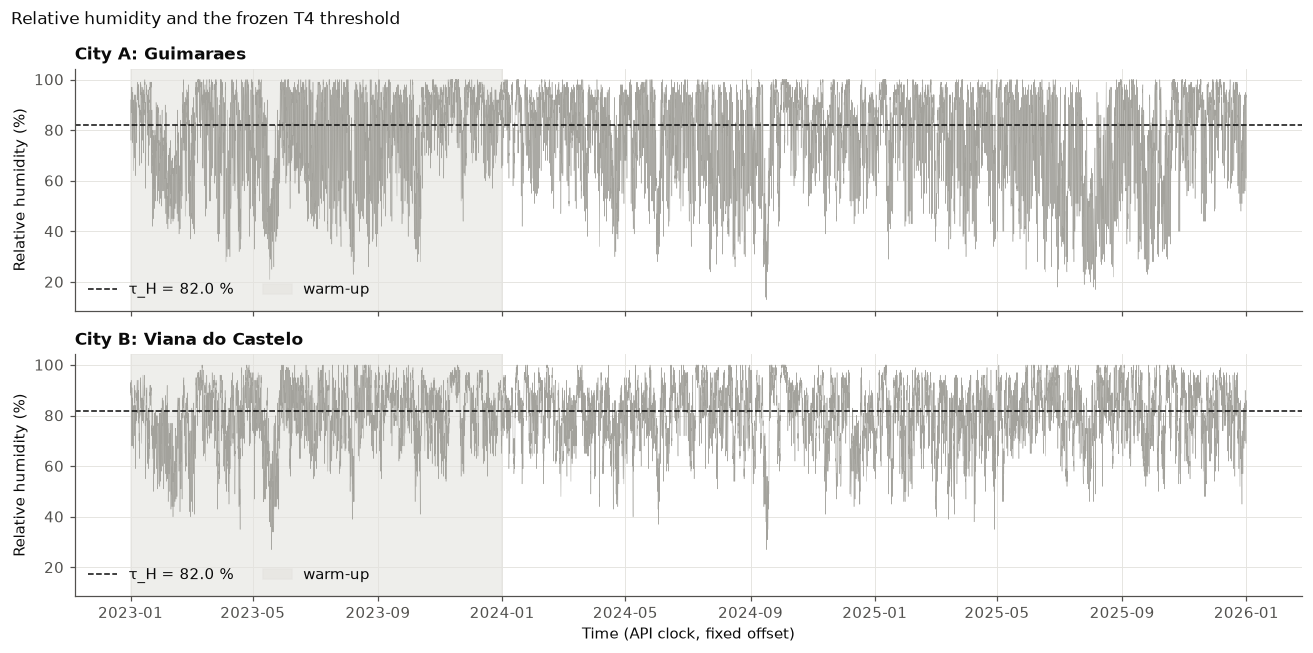

In [12]:
fig = plots.humidity_with_threshold(prepared, cfg)
plots.save(fig, cfg, "shared_01_humidity_with_threshold")
plt.show()

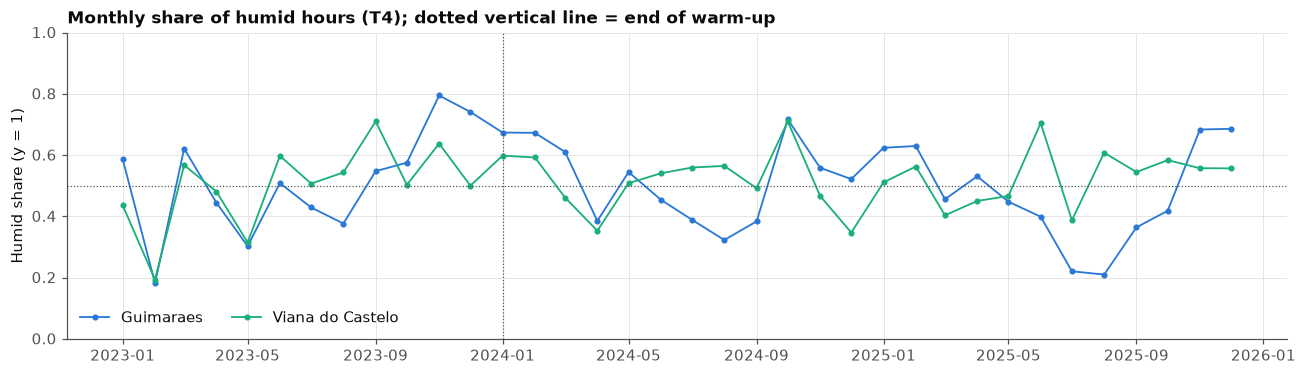

In [13]:
fig = plots.monthly_humid_share(prepared, cfg)
plots.save(fig, cfg, "shared_02_monthly_humid_share")
plt.show()

The class distribution table confirms that both cities are close to balanced in both phases, so the frozen threshold transfers well to the evaluation period.

- **Guimarães:** The warm-up is 51.1% humid. In evaluation it drops slightly to 49.5%, so it's almost perfectly balanced.
- **Viana do Castelo:** The warm-up is exactly 50% (as expected from the median). In evaluation it rises to 52.2% humid, a small shift toward the humid class.
- **Interpretation:** The shifts are small (at most ~2 percentage points), so 2023 was a reasonably typical year and τ_H didn't drift much. The limitation from fixing τ_H on one year exists, but it has little effect here.

**Evaluation metrics choice:** With a near 50/50 split, Accuracy is a fair headline metric for the full evaluation period. Macro-F1 should be reported next to it, because it weights both classes equally and would expose a model that favours one class. Precision and Recall for the humid class, plus the confusion matrix, will show where the errors are, for example whether a model misses humid hours or raises false alarms. This matters more for Viana, which leans slightly humid, and for seasonal subsets, where the monthly plot shows strong imbalance (especially Guimarães in summer).

## 10. Protocol checks: temporal-alignment checklist

**Requirement (Ch. 7.1, 12, 20):** the handbook's checklist as assertions (`data.protocol_checks`). If any check fails, the notebook stops.
The **leakage test** (`features.check_no_leakage`) corrupts the future from row *t* on and asserts that the features up to *t* do not change. It also corrupts the past and asserts that they *do* change (positive control).
The **scaler check** runs inside `features.make_streams`, which raises an error if a row used to fit the scaler is not strictly before the evaluation start.

In [14]:
checks = data.protocol_checks(prepared, cfg)
for k, raw in prepared["raw"].items():
    check_no_leakage(raw, prepared["tau"], cfg)
    checks[f"no feature leakage ({CITIES[k]['name']})"] = True
make_streams(prepared, cfg)  # raises if the scaler would see evaluation rows
checks["scaler fitted on warm-up rows only"] = True
checks.to_frame()

,passed
timestamps strictly increasing (both cities),True
regular 1 h steps (both cities),True
identical timestamps in both cities,True
identical warm-up mask in both cities,True
warm-up ends before evaluation starts,True
tau_H uses only warm-up rows,True
tau_H reproducible from warm-up data,True
y == 1 <=> H_t >= tau_H,True
invalid rows have no label,True
no feature leakage (Guimaraes),True


## 11. Save the records

**Requirement (Ch. 15, 15.2):** results must be traceable to code, configuration and data. The clean streams are **not** saved: they are rebuilt from the raw snapshots by `prepare_frames(cfg)` every time, so no copy can go stale. What is saved is the record of what was frozen (`data.save_protocol_records`).

| File | Content | Used for |
|---|---|---|
| `results/config_part1.json` | frozen protocol: τ_H, warm-up, period, cities, raw files, grid points, valid ranges, flagged rows, seed, versions | audit record of what was frozen before evaluation |
| `results/configurations.csv` | every parameter of `config.yaml` (flattened, e.g. `protocol.warmup_months, 12`) + frozen values + package versions, one per row | reproducibility (Ch. 15): exactly which settings, seed and versions produced the results |
| `results/stream_construction_summary.csv` | per city: grid point, elevation, period, hours, flagged rows, warm-up / evaluation hours, τ_H, humid share in warm-up and evaluation | the table for the report section *Data and Stream Construction* |

These files are **outputs only**: no notebook or module reads them back (every notebook calls `prepare_frames` instead), so they can never feed a stale value into the analysis. They are rewritten each time this notebook runs.
`config_part1.json` and `configurations.csv` overlap. The JSON is the more complete record, and the CSV is the same information as a flat two-column table.

In [15]:
summary = data.save_protocol_records(prepared, cfg)
summary

,Guimaraes,Viana do Castelo
role,City A,City B
"grid point (lat, lon)","41.441, -8.288","41.722, -8.857"
elevation (m),170.0,15.0
period,2023-01-01 to 2025-12-31,2023-01-01 to 2025-12-31
hours (common timeline),26304,26304
rows flagged invalid,0,0
warm-up hours,8760,8760
evaluation hours,17544,17544
"tau_H (pooled, %)",82.0,82.0
"humid share, warm-up",0.511,0.5


## Next

1. **Each student, in their own notebook:** `01_cityA_guimaraes` (Khadija Belhamra) / `02_cityB_viana_do_castelo` (Victoriya Mokhovikova). Profile each city, run the five models on it with the shared protocol, experiment, interpret. Each notebook saves `results/metrics_<city>.csv` and `results/history_<city>.csv`.
2. **Together:** `03_shared_comparison` pairs both students' results for the final report.